# PRIMs Tutorial — Unit 2: Variable Binding, Multiple Skills, the Multilevel Architecture

*Notebook version for pyprims. Open it from the `Unit 2` folder.*

In [1]:
from pyprims.notebook import Session, Dashboard, figure, plot_batch, read_batch
from IPython.display import Image

def show_model(path):
    """Print a model file."""
    print(open(path, encoding="utf-8").read())

## Variable binding in skills

In the examples of Unit 1, specific values such as `say` and `count-fact` were part of the operators. The disadvantage is that this makes operators quite specific, and therefore less suitable for reuse. To make operators more general, we can bind the specific values at the level of the skill, and keep the operators general.

In the count and semantic examples of Unit 1, the conditions and actions of some of the operators were identical, but each still required a separate operator node because their specific values were different. We can generalize this with a more generic operator, such as:

```
operator start-iteration {
    V1 <> nil
    WM1 = nil
==>
    V1 -> WM1
    *fact-type -> RT1
    V1 -> RT2
    *action -> AC1
    V1 -> AC2
}
```

For the counting task we can then instantiate `*fact-type` with `count-fact` and `*action` with `say`, while in the semantic task we instantiate them with `property` and `subvocalize`. Note the notation: a constant preceded by an asterisk is a **variable** whose value is bound to the active skill.

We can do the binding in the script. In the case of counting, we can give the skill a more generic name such as `iterate`, and then bind the variables to values:

```
add-binding("fact-type","count-fact")
add-binding("action","say")
add-binding("final-action","say")
add-binding("final-response","stop")
```

Alternatively, we can create the bindings in an operator, which is what the example model does:

```
operator set-instruction {
    G1 = count
==>
    count-fact -> *fact-type
    say -> *action
    say -> *final-action
    stop -> *final-response
    iterate -> G1
}
```

Here is the complete model, `count-rev1.prims`:

In [2]:
show_model("count-rev1.prims")

// More general version of count

define task count {
  initial-skills: (count)
  default-activation: 1.0 // All chunks defined in this model receive a fixed baselevel activation of 1.0
  ol: t
  rt: -2.0
  lf: 0.2
  default-operator-self-assoc: 0.0
  egs: 0.05
  retrieval-reinforces: t
//  bindings-in-dm: t
}

define skill count {
	operator set-instruction {
		G1 = count
	==>
		count-fact -> *fact-type
		say -> *action
		say -> *final-action
		stop -> *final-response
		iterate -> G1
	}
}


define skill iterate {
//  Start iteration
  operator start-iteration {
   V1 <> nil  // There has to be a visual input with the starting number
   WM1 = nil  // Imaginal should be empty
  ==>
   V1 -> WM1 
   *fact-type -> RT1 
   V1 -> RT2
   *action -> AC1 
   V1 -> AC2
   }

//    Iterate as long V2 does not match the final goal
  operator iterate {
    RT2 = WM1
    V2 <> WM1
   ==>
    RT3 -> WM1
    *fact-type -> RT1
    RT3 -> RT2
    *action -> AC1
    RT3 ->AC2
  }

//    Stop when reachin

Let us run it and look at the operators it uses (trace level 1):

In [3]:
s = Session(seed=1)
s.load("count-rev1.prims")
s.run(1)
print(s.trace(1))

Counting from three to four 
0.00  Starting new trial
0.00  *** Retrieved operator set-instruction with latency 0.001
1.55  *** Retrieved operator start-iteration with latency 0.001
3.80  *** Retrieved operator iterate0 with latency 0.002
6.56  *** Retrieved operator final with latency 0.001
7.81  End of trial


`set-instruction` binds the variables and puts `iterate` in G1, after which the general operators of the `iterate` skill do the counting.

We can now instantiate the same skill for the semantic task (`semantic-rev1.prims`):

```
operator set-instruction {
    G1 = semantic
==>
    property -> *fact-type
    sub-vocalize -> *action
    say -> *final-action
    yes -> *final-response
    no -> *final-response-negative
    iterate -> G1
}
```

`semantic-rev1.prims` defines **only** this skill, plus the facts and the script: it reuses the `iterate` skill of the count model. On its own, the model therefore cannot do anything after `set-instruction`:

In [4]:
alone = Session(seed=1)
alone.load("semantic-rev1.prims")
alone.run(1)
print(alone.trace(2))

Is tulip a animal ? 
0.00  Starting new trial
0.00  *** Retrieved operator set-instruction with latency 0.001
1.85     No matching operator found
3.33  End of trial


/tmp/ipykernel_465/3310015686.py:3: NoOperatorWarning: In 1 of 1 trial the model stopped because no operator matched. The rest of the script then ran without the model, so last-action() may be empty. trace(2) shows the last trial.
  alone.run(1)


But with the count model loaded first, the semantic task works, and uses the operators (and the compiled productions) of `iterate`:

Is lion a plant ? 
295.11  Starting new trial
295.12  *** Retrieved operator set-instruction29 with latency 0.003
296.68  *** Retrieved operator start-iteration with latency 0.010
297.99  *** Retrieved operator iterate0 with latency 0.001
298.73  *** Retrieved operator iterate0 with latency 0.002
299.46  *** Retrieved operator iterate0 with latency 0.004
301.58  *** Retrieved operator final-fail with latency 0.001
302.49  End of trial


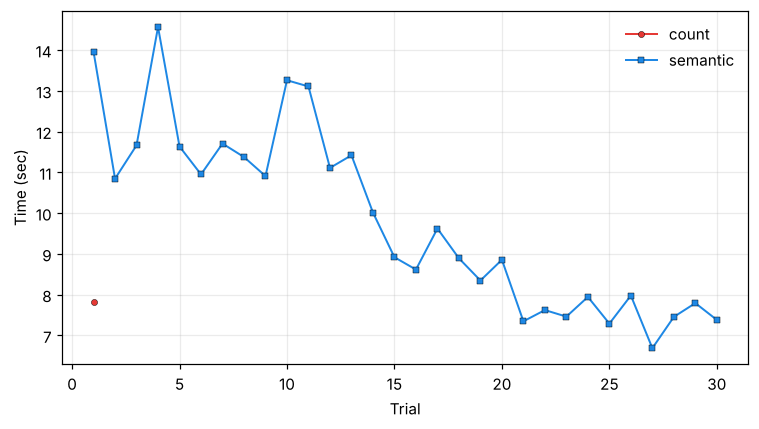

In [5]:
s.load("semantic-rev1.prims")      # s already has count-rev1, and has run it once
s.run(30)
print(s.trace(1))
ax = s.plot_results()

### Bindings in declarative memory

By default, bindings are "perfect": they have no time cost or chance of failure. If you set the parameter `bindings-in-dm: t`, bindings are stored in and retrieved from declarative memory, with the associated time costs and probability of failure. In `count-rev1.prims` this line is commented out. You can uncomment it in the file, or, as we do here, load a modified copy of the model text:

In [6]:
import re
text = open("count-rev1.prims").read()
text_dm = re.sub(r"//\s*bindings-in-dm", "bindings-in-dm", text)   # uncomment the parameter

perfect = Session(seed=1); perfect.load(text);    perfect.run(30)
in_dm   = Session(seed=1); in_dm.load(text_dm);   in_dm.run(30)
print("mean time of the last 10 trials, perfect bindings: %.2f s" % (sum(perfect.results[-10:]) / 10))
print("mean time of the last 10 trials, bindings in DM:   %.2f s" % (sum(in_dm.results[-10:]) / 10))
print()
print(in_dm.trace(2))

mean time of the last 10 trials, perfect bindings: 6.78 s
mean time of the last 10 trials, bindings in DM:   10.24 s

Counting from one to two 
364.80  Starting new trial
364.81  *** Retrieved operator set-instruction with latency 0.005
366.86  *** Retrieved operator start-iteration with latency 0.005
367.81  Retrieving cf1 (latency = 0.063)
367.81  Saying one  (latency = 0.241)
368.35  *** Retrieved operator iterate0 with latency 0.001
369.30  Retrieving cf2 (latency = 0.037)
369.30  Saying two  (latency = 0.304)
370.14  *** Retrieved operator final with latency 0.001
371.09  Saying stop  (latency = 0.318)
371.40  End of trial


With bindings in memory, every binding that an operator needs has to be retrieved, which takes time. Each `set-instruction` also adds new binding chunks to declarative memory (the script function `purge-bindings()` removes them):

In [7]:
in_dm.dm(type="binding").head()

,type,activation,base_level,spreading,references,fan,slots
name,,,,,,,
binding1033,binding,-0.096258,-0.210706,0.0,1,0,slot1=currentGoalChunk1027 slot2=final-action ...
binding1034,binding,-0.210981,-0.149723,0.0,1,0,slot1=currentGoalChunk1027 slot2=final-respons...
binding1032,binding,-0.364797,-0.210706,0.0,1,0,slot1=currentGoalChunk1027 slot2=action slot3=say
binding983,binding,-0.388327,-0.832279,0.0,1,0,slot1=currentGoalChunk977 slot2=final-action s...
binding950,binding,-0.415441,-1.015689,0.0,1,0,slot1=currentGoalChunk946 slot2=fact-type slot...


Although we have now unified the two models, the result is still not entirely satisfactory, because the `iterate` skill has limited use. Suppose you want to use the result of the iteration for something else, or the source of your iteration is not in the input buffer, but the result of something else? To make a more plausible model with reusable skills, we need to break down the task into several skills, and connect these together.

## Tasks consisting of multiple skills

We encounter new tasks every day, many of which we can carry out without instruction or training. The probable reason is that these new tasks are combinations of things we already know how to do. Up to now, a task has corresponded to a single skill. However, a task may consist of several skills, possibly in parallel or with some imposed control structure.

In the earlier examples, the skill was stored in slot G1. We can also store skills in G2 and up. Each skill can be associated with its own set of operators. Skills in the goal buffer spread activation to their associated operators (with an $S_{ji}$ of `default-operator-assoc`). Operators of a particular skill are also associated with each other (with an $S_{ji}$ of `default-inter-operator-assoc`), which increases the likelihood of using an operator of the same skill as long as there are applicable ones. Finally, in most models we don't want the same operator to fire repeatedly, so operators are negatively associated with themselves (`default-operator-self-assoc`). Operators can put new skills in G slots (e.g., `count-one -> G2`), and can remove them (by putting nil into them, e.g., `nil -> G2`). By making goals variable themselves, we can connect skills together in a flexible way (e.g., `*next-skill -> G2`).

If we want to start the model with a number of skills already active, we add these to the `initial-skills:` declaration: the first in the list is placed in G1, the second in G2, and so on.

To explore this, we take the count and semantic examples, and break up the iterate skill into three skills: **read**, **iterate** and **respond** (`count-rev2.prims`). The read and respond skills are quite simple, but they decouple the iterate skill from perception and action. In addition, each task has its own skill that instantiates the bindings and switches to the read skill.

The `count` skill initiates the variables and then switches to the `read` skill:

```
define skill count {
    operator set-instruction {
        G1 = count
    ==>
        count-fact -> *fact-type
        say -> *action
        say -> *respond-action
        stop -> *success-arg
        iterate -> *next-skill
        respond -> *final-action-skill
        read -> G1
    }
}
```

The `read` skill reads the two numbers:

```
define skill read {
    operator read-for-two-items {
        V1 <> nil
        V2 <> nil
        WM1 = nil
    ==>
        V1 -> WM1
        V2 -> WM2
    }
    operator switch-to-next-skill {
        V1 = WM1
    ==>
        *next-skill -> G1
    }
}
```

The first operator transfers the two items in the input buffer to working memory. The second transfers control to the next skill by placing it in G1. Here the read skill transfers control to the iterate skill, because the count skill specified this. Because this is only a temporary binding, we can use the read skill for other purposes as well. Indeed, we could expand it to read an arbitrary number of words, one at a time.

The `iterate` skill no longer carries out a final action itself, but transfers control to another skill, with an argument that depends on the success or failure of the iteration. For counting, the iteration should never fail, so we do not need a failure argument:

```
operator final {
    WM2 = WM3
==>
    *final-action-skill -> G1
    *success-arg -> *respond-arg
}
operator final-fail {
    WM2 <> WM3
    RT1 = error
==>
    *final-action-skill -> G1
    *failure-arg -> *respond-arg
}
```

The `respond` skill is very simple; it just carries out an action:

```
define skill respond {
    operator carry-out-action {
        G1 <> nil // Operators require at least one condition
    ==>
        *respond-action -> AC1
        *respond-arg -> AC2
        nil -> G1
    }
}
```

We can now reuse all these skills for the semantic example (`semantic-rev2.prims`). For this example we do need a failure response ("no"). We only change the bindings:

```
operator set-instruction {
    G1 = semantic
==>
    property -> *fact-type
    sub-vocalize -> *action
    say -> *respond-action
    yes -> *success-arg
    iterate -> *next-skill
    respond -> *final-action-skill
    no -> *failure-arg
    read -> G1
}
```

This operator becomes very bloated, but it is a placeholder for a probably more elaborate process of interpreting an instruction. Alternatively, you can do the same in the script:

```
add-binding("next-skill","iterate")
add-binding("action","sub-vocalize")
add-binding("fact-type","property")
add-binding("final-action-skill","respond")
add-binding("respond-action","say")
add-binding("success-arg","yes")
add-binding("failure-arg","no")
```

Let us run count first, and then semantic, in the same session. Note that `count-rev2.prims` has `bindings-in-dm: t`.

Is tulip a animal ? 
1135.10  Starting new trial
1135.11  *** Retrieved operator set-instruction2495 with latency 0.004
1136.36  *** Retrieved operator read-for-two-items with latency 0.003
1136.71  *** Retrieved operator switch-to-next-skill with latency 0.002
1136.77  *** Retrieved operator start-iteration with latency 0.005
1137.19  *** Retrieved operator iterate0 with latency 0.002
1137.30  *** Retrieved operator iterate0 with latency 0.004
1138.83  *** Retrieved operator final-fail with latency 0.001
1139.48  *** Retrieved operator carry-out-action with latency 0.004
1140.13  End of trial


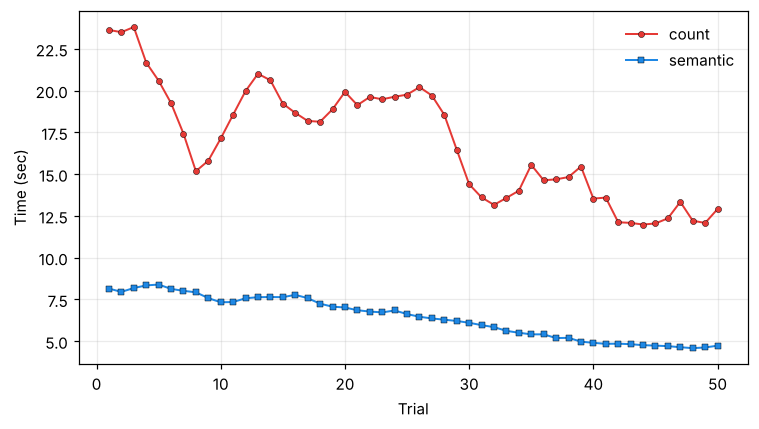

In [8]:
ms = Session(seed=2)
ms.load("count-rev2.prims");    ms.run(50)
ms.load("semantic-rev2.prims"); ms.run(50)
print(ms.trace(1))
ax = ms.plot_results(average_window=5)

The task graph at level 1 shows the tasks, the skills and their operators. The semantic task adds only a single skill with one operator (`set-instruction`); everything else is shared:

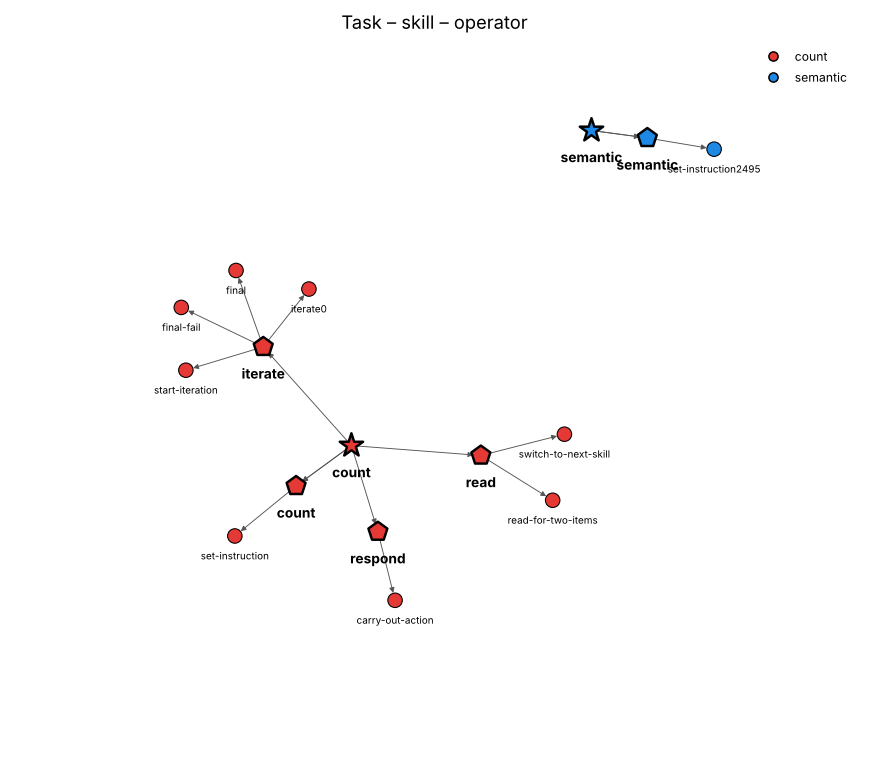

In [9]:
ax = ms.plot_graph(1, seed=1)

## The multilevel architecture

The interesting aspect of the semantic model is that we only need to add an operator that instantiates some bindings, and can then reuse all the other skills from the count model. This gives us, more or less, a higher-level means of building cognitive models. If the skills we need are already encoded in memory, the only thing we need to do is connect them together and provide the appropriate instantiations. One of the goals of PRIMs is to provide multiple levels of abstraction in modeling. We started, in Unit 1, with a relatively traditional abstraction level that is similar to ACT-R. But now we see that we can also build models at a higher level of abstraction.

The figure illustrates the basic idea behind the multilevel architecture: knowledge has different levels of abstraction, which means we can have learning and transfer at multiple levels. We have already seen that transfer can occur at three levels: by overlapping PRIMs (Unit 1), by overlapping operators (the first example in this unit), or by overlapping skills (the last example).

In later units we will examine an even higher level of abstraction, in which the model itself creates the representation of the skill, and a lower level, where the model has to discover which combinations of PRIMs lead to a reward in a very simple task.

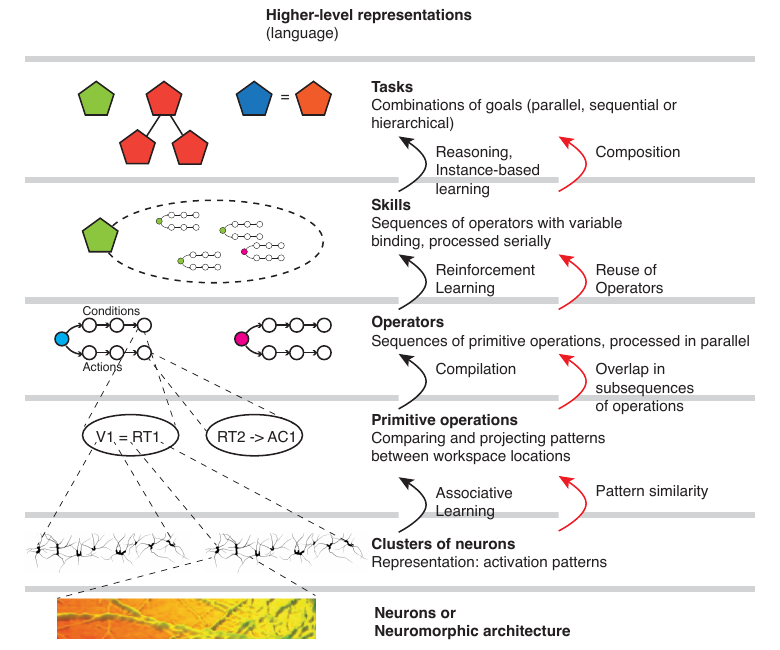

In [10]:
Image("figures/multilevel.png", width=650)

## Assignment

The iteration skill in the count/semantic example is still limited to performing an action on the item that we iterate over. However, we might want to do more with an item than just a primitive action. In `count-rev3.prims`, control is handed over to another skill on each iteration by the following operator:

```
operator do-sub-skill {
    RT1 = *fact-type
==>
    RT3 -> WM3
    *sub-skill -> G1
}
```

This operator switches to a different skill after retrieving a next fact and placing it in WM3. After the sub-skill has done something with the contents of WM3 and has returned control to the iterate skill, iterate can proceed with the next item (assuming we are not done yet):

```
operator retrieve-next {
    RT1 = nil
    WM3 <> nil
    WM2 <> WM3
==>
    *fact-type -> RT1
    WM3 -> RT2
}
```

In the count example, saying the number is still the only thing we do, so the actual sub-skill is pretty simple:

```
define skill do-action {
    operator do-action-on-WM3 {
        WM3 <> nil
    ==>
        *action -> AC1
        WM3 -> AC2
        *main-skill -> G1
    }
}
```

Of course, we need to tie everything together when we instantiate the skills:

```
add-binding("next-skill","iterate")
add-binding("action","say")
add-binding("fact-type","count-fact")
add-binding("final-action-skill","respond")
add-binding("respond-action","say")
add-binding("respond-arg","stop")
add-binding("sub-skill","do-action")
add-binding("main-skill","iterate")
```

Here we specify that `do-action` is the sub-skill of `iterate`, and `iterate` is the skill to return to when `do-action` is done. Here is the complete model:

In [11]:
show_model("count-rev3.prims")

// More general version of count

define task count {
  initial-skills: (read)
  default-activation: 1.0 // All chunks defined in this model receive a fixed baselevel activation of 1.0
  ol: t
  rt: -2.0
  lf: 0.2
  default-operator-self-assoc: 0.0
  egs: 0.05
  retrieval-reinforces: t
}

define skill read {
	operator read-for-two-items {
		V1 <> nil
		V2 <> nil
		WM1 = nil
	==>
		V1 -> WM1
		V2 -> WM2
	}
	operator switch-to-next-skill {
		V1 = WM1
	==>
		*next-skill -> G1
	}
}

define skill iterate {
//  Start iteration
  operator start-iteration {
   WM3 = nil  // Slot we use for iterator is empty
  ==>
   WM1 -> WM3	
   *sub-skill -> G1
   }

  operator do-sub-skill {
   RT1 = *fact-type
   ==>
   RT3 -> WM3
   *sub-skill -> G1
  }

//    Iterate as long WM2 does not match the final goal
  operator retrieve-next {
    RT1 = nil
    WM3 <> nil
    WM2 <> WM3
   ==>
    *fact-type -> RT1
    WM3 -> RT2
  }

//    Stop when reaching final match
  operator final {
    WM2 = WM3
    RT1 

So far, the model still does exactly the same as the original count model. A possible new use for this way of specifying the skill is to extend the semantic model. Up to now, we have only been able to ask category questions. But we would also like to ask questions such as "Can a robin fly?", where flying is an attribute of bird. We can do this by switching to a sub-skill that checks whether the current item in the iteration has the attribute.

The next cell contains `semantic-rev3.prims`. It has a number of attributes in its list of facts, and a number of additional questions in the script. It also defines an additional skill that does the fact checking, `attempt-retrieve`. This skill tries to retrieve a fact based on WM3 and WM2, and switches to one skill if it succeeds, and to another skill if it fails. It also defines `alt-respond`, a second way to respond. The other skills (`read`, `iterate`, `respond`) come from `count-rev3.prims`, which we load first.

**The assignment is to finish the model.** The only thing you need to do is instantiate the skills: replace each `XXX` in the script by the right value (in quotes), and run the cell again. Then run the test cell below it.

In [12]:
sr = Session(seed=3)
sr.load("count-rev3.prims")
_ = sr.run(20)          # some practice on counting first

In [13]:
%%prims sr
// Semantic, but now with also answers questions about attributes

define task semantic {
  initial-skills: (read)
  default-activation: 1.0 
  ol: t
  rt: -2.0
  lf: 0.2
  egs: 0.05
  retrieval-reinforces: t
}

define skill attempt-retrieve {
	operator start-retrieve {
		WM2 <> nil
		WM3 <> nil
		RT1 = nil
	==>
		*attribute-fact-type -> RT1
		WM3 -> RT2
		WM2 -> RT3
	}

	operator on-success {
		RT1 = *attribute-fact-type
	==>
		*retrieve-success-skill -> G1
	}

	operator on-fail {
		RT1 = error
	==>
		*retrieve-fail-skill -> G1
	}
}


define skill alt-respond {
	operator carry-out-action {
		G1 <> nil // Operators require at least one condition
		==>
		*alt-respond-action -> AC1
		*alt-respond-arg -> AC2
		nil -> G1
	}
}

define action say {
  latency: 0.3
  noise: 0.1
  distribution: uniform
  output: Saying
}

define facts {

    (sem1  property  lion  mammal)
    (sem2  property  mammal  animal)
    (sem3  property  animal living-thing)
    (sem4  property  plant living-thing)
    (sem5  property  tulip plant)
    (sem6  property  bird animal)
    (sem7  property  tweety bird)
    (sem8  property  robin bird)
	(sem11 has-attribute bird flies)
	(sem12 has-attribute living-thing cells)
	(sem13 has-attribute tulip flower)
	(sem14 has-attribute bird eggs)
	(sem15 has-attribute animal blood)
	(sem16 has-attribute plant roots)
}

/// Assignment: Fill in the XXX's in the script

define script {
	add-binding("next-skill",XXX)
	add-binding("fact-type",XXX)
	add-binding("attribute-fact-type",XXX)
	add-binding("final-action-skill",XXX)
	add-binding("fail-skill",XXX)
	add-binding("respond-action",XXX)
	add-binding("respond-arg",XXX)
	add-binding("alt-respond-action",XXX)
	add-binding("alt-respond-arg",XXX)
	add-binding("sub-skill",XXX)
	add-binding("retrieve-success-skill",XXX)
	add-binding("retrieve-fail-skill",XXX)
    pairs = [["lion","flies","no"], ["robin","flies","yes"], ["mammal","cells","yes"], ["plant","roots","yes"], ["lion","living-thing","yes"], ["tulip","animal","no"], ["mammal","living-thing","yes"], ["lion","plant","no"]]
    pairno = random(length(pairs))
    pair = pairs[pairno]
    print("Has",pair[0],"the attribute",pair[1],"?")
    screen(pair[0],pair[1])
    run-until-action("say")
    issue-reward()
    trial-end()
}

Loaded task 'semantic' into sr (tasks: count, semantic)


In [14]:
def test(session, trials=20):
    """Run some trials, then show the trace of the last one and the answers given."""
    try:
        session.run(trials)
    except NameError:
        print("The script still contains XXX: fill in all the bindings first.")
        return
    print(session.trace(1))
    answers = [line for line in session.trace(0).splitlines() if "?" in line]
    print("Last question:", answers[-1] if answers else "-")
    said = [(d.p1, d.p2) for d in session.model.output_data if d.event_type == "action" and d.p1 == "say"]
    print("Model said:", said)

test(sr)

The script still contains XXX: fill in all the bindings first.


When the model works, change the script so that it checks whether the answer is correct (the third element of each question in `pairs`) and plots the accuracy with `plot-point(1)` or `plot-point(0)`, as `count-learn.prims` in Unit 3 does.

**Next:** Unit 3 looks at how operators are selected, and how the associations between skills and operators can be learned.